In [ ]:
# Naive Bayes & KNN
# Datasets:
#   - SMS Spam Collection (Kaggle CSV version): https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
#   - Iris: built into sklearn, no download needed

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.datasets import load_iris

# ============================================================
# PART 1 - Naive Bayes (SMS Spam Collection - text classification)
# ============================================================

# Kaggle's spam.csv is comma-separated, has a header, and needs latin-1 encoding
# (plain utf-8 will throw a UnicodeDecodeError on this file)
df = pd.read_csv(
    r"C:\Users\syin\Downloads\archive (37)\spam.csv",
    encoding="latin-1"
)

print("Columns found:", df.columns.tolist())

# Kaggle version usually has columns like v1, v2, Unnamed: 2, Unnamed: 3, Unnamed: 4
# (the "Unnamed" ones are junk - mostly empty). Grab the first two columns
# positionally instead of relying on exact column names, then rename them.
df = df.iloc[:, :2]
df.columns = ["label", "message"]

print(df.shape)
print(df.head())
print(df["label"].value_counts())

# ---- 1. Encode target ----
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

# sanity check - if this prints any NaN count > 0, the label values weren't
# exactly "ham"/"spam" (e.g. extra whitespace) and need a .str.strip() above
print("Unmapped labels:", df["label_num"].isnull().sum())

# ---- 2. Quick look at class balance ----
sns.countplot(x="label", data=df)
plt.title("Ham vs Spam Count")
plt.show()

# spam is usually a minority class here - worth keeping in mind when reading accuracy

# ---- 3. Train/test split (on raw text, before vectorizing) ----
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["message"], df["label_num"], test_size=0.2, random_state=42, stratify=df["label_num"]
)

# ---- 4. Convert text to numeric features (Bag of Words) ----
# fit on train only, transform both - same rule as scaling, avoids leakage
vectorizer = CountVectorizer(stop_words="english")
X_train_vec = vectorizer.fit_transform(X_train_text)
X_test_vec = vectorizer.transform(X_test_text)

print("Vocabulary size:", len(vectorizer.vocabulary_))

# ---- 5. Fit Naive Bayes ----
# MultinomialNB is the standard choice for word-count style text features
nb = MultinomialNB()
nb.fit(X_train_vec, y_train)

# ---- 6. Predict and evaluate ----
y_pred = nb.predict(X_test_vec)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# ---- 7. Try it on a couple of made-up messages ----
sample_messages = [
    "Congratulations! You have won a free ticket, call now to claim your prize",
    "Hey, are we still meeting for lunch tomorrow?"
]
sample_vec = vectorizer.transform(sample_messages)
sample_pred = nb.predict(sample_vec)

for msg, pred in zip(sample_messages, sample_pred):
    label = "SPAM" if pred == 1 else "HAM"
    print(f"[{label}] {msg}")


# ============================================================
# PART 2 - KNN (Iris - predict species from flower measurements)
# ============================================================

iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df["species"] = iris.target

X_iris = iris_df.drop(columns=["species"])
y_iris = iris_df["species"]

# ---- 8. Train/test split ----
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_iris, y_iris, test_size=0.2, random_state=42, stratify=y_iris
)

# ---- 9. Scale features - KNN is distance-based, scaling matters a lot here ----
scaler = StandardScaler()
Xi_train_scaled = scaler.fit_transform(Xi_train)
Xi_test_scaled = scaler.transform(Xi_test)

# ---- 10. Try different values of k and see what works best ----
k_values = range(1, 21)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(Xi_train_scaled, yi_train)
    pred = knn.predict(Xi_test_scaled)
    accuracies.append(accuracy_score(yi_test, pred))

plt.plot(k_values, accuracies, marker="o")
plt.title("KNN Accuracy vs k")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Accuracy")
plt.show()

best_k = k_values[np.argmax(accuracies)]
print(f"Best k: {best_k}, Accuracy: {max(accuracies):.4f}")

# ---- 11. Fit final KNN model with best k ----
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(Xi_train_scaled, yi_train)
yi_pred = knn_final.predict(Xi_test_scaled)

print("\nConfusion Matrix:\n", confusion_matrix(yi_test, yi_pred))
print("\nClassification Report:\n", classification_report(yi_test, yi_pred))

In [1]:
# Naive Bayes & KNN
# Datasets:
#   - SMS Spam Collection (Kaggle CSV version): https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
#   - Iris: built into sklearn, no download needed

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.datasets import load_iris

Columns found: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']
(5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64
Unmapped labels: 0


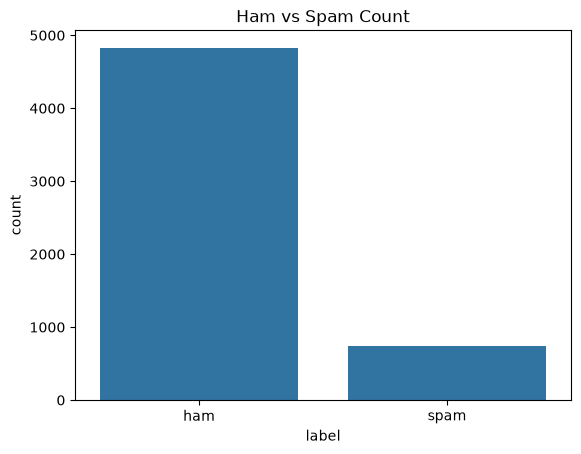

Vocabulary size: 7440
Accuracy: 0.9838565022421525

Confusion Matrix:
 [[960   6]
 [ 12 137]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       966
           1       0.96      0.92      0.94       149

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115

[SPAM] Congratulations! You have won a free ticket, call now to claim your prize
[HAM] Hey, are we still meeting for lunch tomorrow?


In [2]:
# ============================================================
# PART 1 - Naive Bayes (SMS Spam Collection - text classification)
# ============================================================

# Kaggle's spam.csv is comma-separated, has a header, and needs latin-1 encoding
# (plain utf-8 will throw a UnicodeDecodeError on this file)
df = pd.read_csv(
    r"C:\Users\syin\Downloads\archive (37)\spam.csv",
    encoding="latin-1"
)

print("Columns found:", df.columns.tolist())

# Kaggle version usually has columns like v1, v2, Unnamed: 2, Unnamed: 3, Unnamed: 4
# (the "Unnamed" ones are junk - mostly empty). Grab the first two columns
# positionally instead of relying on exact column names, then rename them.
df = df.iloc[:, :2]
df.columns = ["label", "message"]

print(df.shape)
print(df.head())
print(df["label"].value_counts())

# ---- 1. Encode target ----
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

# sanity check - if this prints any NaN count > 0, the label values weren't
# exactly "ham"/"spam" (e.g. extra whitespace) and need a .str.strip() above
print("Unmapped labels:", df["label_num"].isnull().sum())

# ---- 2. Quick look at class balance ----
sns.countplot(x="label", data=df)
plt.title("Ham vs Spam Count")
plt.show()

# spam is usually a minority class here - worth keeping in mind when reading accuracy

# ---- 3. Train/test split (on raw text, before vectorizing) ----
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["message"], df["label_num"], test_size=0.2, random_state=42, stratify=df["label_num"]
)

# ---- 4. Convert text to numeric features (Bag of Words) ----
# fit on train only, transform both - same rule as scaling, avoids leakage
vectorizer = CountVectorizer(stop_words="english")
X_train_vec = vectorizer.fit_transform(X_train_text)
X_test_vec = vectorizer.transform(X_test_text)

print("Vocabulary size:", len(vectorizer.vocabulary_))

# ---- 5. Fit Naive Bayes ----
# MultinomialNB is the standard choice for word-count style text features
nb = MultinomialNB()
nb.fit(X_train_vec, y_train)

# ---- 6. Predict and evaluate ----
y_pred = nb.predict(X_test_vec)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# ---- 7. Try it on a couple of made-up messages ----
sample_messages = [
    "Congratulations! You have won a free ticket, call now to claim your prize",
    "Hey, are we still meeting for lunch tomorrow?"
]
sample_vec = vectorizer.transform(sample_messages)
sample_pred = nb.predict(sample_vec)

for msg, pred in zip(sample_messages, sample_pred):
    label = "SPAM" if pred == 1 else "HAM"
    print(f"[{label}] {msg}")


Columns found: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']
(5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64
Unmapped labels: 0


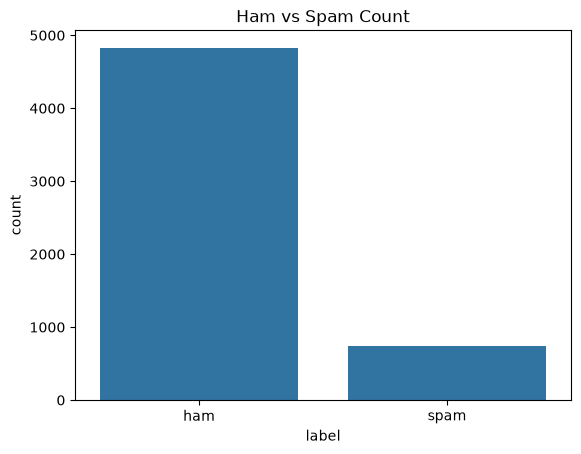

Vocabulary size: 7440
Accuracy: 0.9838565022421525

Confusion Matrix:
 [[960   6]
 [ 12 137]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       966
           1       0.96      0.92      0.94       149

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115

[SPAM] Congratulations! You have won a free ticket, call now to claim your prize


NameError: name 'k' is not defined

In [3]:
# ============================================================
# PART 1 - Naive Bayes (SMS Spam Collection - text classification)
# ============================================================

# Kaggle's spam.csv is comma-separated, has a header, and needs latin-1 encoding
# (plain utf-8 will throw a UnicodeDecodeError on this file)
df = pd.read_csv(
    r"C:\Users\syin\Downloads\archive (37)\spam.csv",
    encoding="latin-1"
)

print("Columns found:", df.columns.tolist())

# Kaggle version usually has columns like v1, v2, Unnamed: 2, Unnamed: 3, Unnamed: 4
# (the "Unnamed" ones are junk - mostly empty). Grab the first two columns
# positionally instead of relying on exact column names, then rename them.
df = df.iloc[:, :2]
df.columns = ["label", "message"]

print(df.shape)
print(df.head())
print(df["label"].value_counts())

# ---- 1. Encode target ----
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

# sanity check - if this prints any NaN count > 0, the label values weren't
# exactly "ham"/"spam" (e.g. extra whitespace) and need a .str.strip() above
print("Unmapped labels:", df["label_num"].isnull().sum())

# ---- 2. Quick look at class balance ----
sns.countplot(x="label", data=df)
plt.title("Ham vs Spam Count")
plt.show()

# spam is usually a minority class here - worth keeping in mind when reading accuracy

# ---- 3. Train/test split (on raw text, before vectorizing) ----
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["message"], df["label_num"], test_size=0.2, random_state=42, stratify=df["label_num"]
)

# ---- 4. Convert text to numeric features (Bag of Words) ----
# fit on train only, transform both - same rule as scaling, avoids leakage
vectorizer = CountVectorizer(stop_words="english")
X_train_vec = vectorizer.fit_transform(X_train_text)
X_test_vec = vectorizer.transform(X_test_text)

print("Vocabulary size:", len(vectorizer.vocabulary_))

# ---- 5. Fit Naive Bayes ----
# MultinomialNB is the standard choice for word-count style text features
nb = MultinomialNB()
nb.fit(X_train_vec, y_train)

# ---- 6. Predict and evaluate ----
y_pred = nb.predict(X_test_vec)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# ---- 7. Try it on a couple of made-up messages ----
sample_messages = [
    "Congratulations! You have won a free ticket, call now to claim your prize",
    "Hey, are we still meeting for lunch tomorrow?"
]
sample_vec = vectorizer.transform(sample_messages)
sample_pred = nb.predict(sample_vec)

for msg, pred in zip(sample_messages, sample_pred):
    label = "SPAM" if pred == 1 else "HAM"
    print(f"[{label}] {msg}")
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(Xi_train_scaled, yi_train)
    pred = knn.predict(Xi_test_scaled)
    accuracies.append(accuracy_score(yi_test, pred))

plt.plot(k_values, accuracies, marker="o")
plt.title("KNN Accuracy vs k")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Accuracy")
plt.show()

best_k = k_values[np.argmax(accuracies)]
print(f"Best k: {best_k}, Accuracy: {max(accuracies):.4f}")

# ---- 11. Fit final KNN model with best k ----
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(Xi_train_scaled, yi_train)
yi_pred = knn_final.predict(Xi_test_scaled)

print("\nConfusion Matrix:\n", confusion_matrix(yi_test, yi_pred))
print("\nClassification Report:\n", classification_report(yi_test, yi_pred))